# 💳 Credit Card Fraud Detection — Unsupervised vs Supervised

Detect fraudulent transactions among 284,807 European card transactions, where **only 0.17% are fraud**.

The project compares two approaches:
1. **Isolation Forest** — unsupervised anomaly detection (no labels needed).
2. **XGBoost** — supervised learning with class weighting for the extreme imbalance.

**Author:** Reda Akram · Computer Science (AI), University of Technology – Baghdad

> **Data:** [Kaggle – Credit Card Fraud Detection (ULB)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). The CSV (~150 MB) is too large for GitHub; download it and place it at `data/creditcard.csv`. Features `V1`–`V28` are PCA components (anonymised for privacy); `Time` and `Amount` are raw.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (classification_report, confusion_matrix, precision_recall_curve,
                             average_precision_score, precision_score, recall_score, f1_score)
from xgboost import XGBClassifier
sns.set_theme(style="whitegrid"); RANDOM_STATE = 42

## 1. Data

In [2]:
df = pd.read_csv("data/creditcard.csv")
print(df.shape, "| missing:", df.isnull().sum().sum(), "| duplicates:", df.duplicated().sum())
df = df.drop_duplicates()
print(df["Class"].value_counts())
print(f"Fraud rate: {df['Class'].mean():.4%}")

(284807, 31) | missing: 0 | duplicates: 1081


Class
0    283253
1       473
Name: count, dtype: int64
Fraud rate: 0.1667%


## 2. EDA

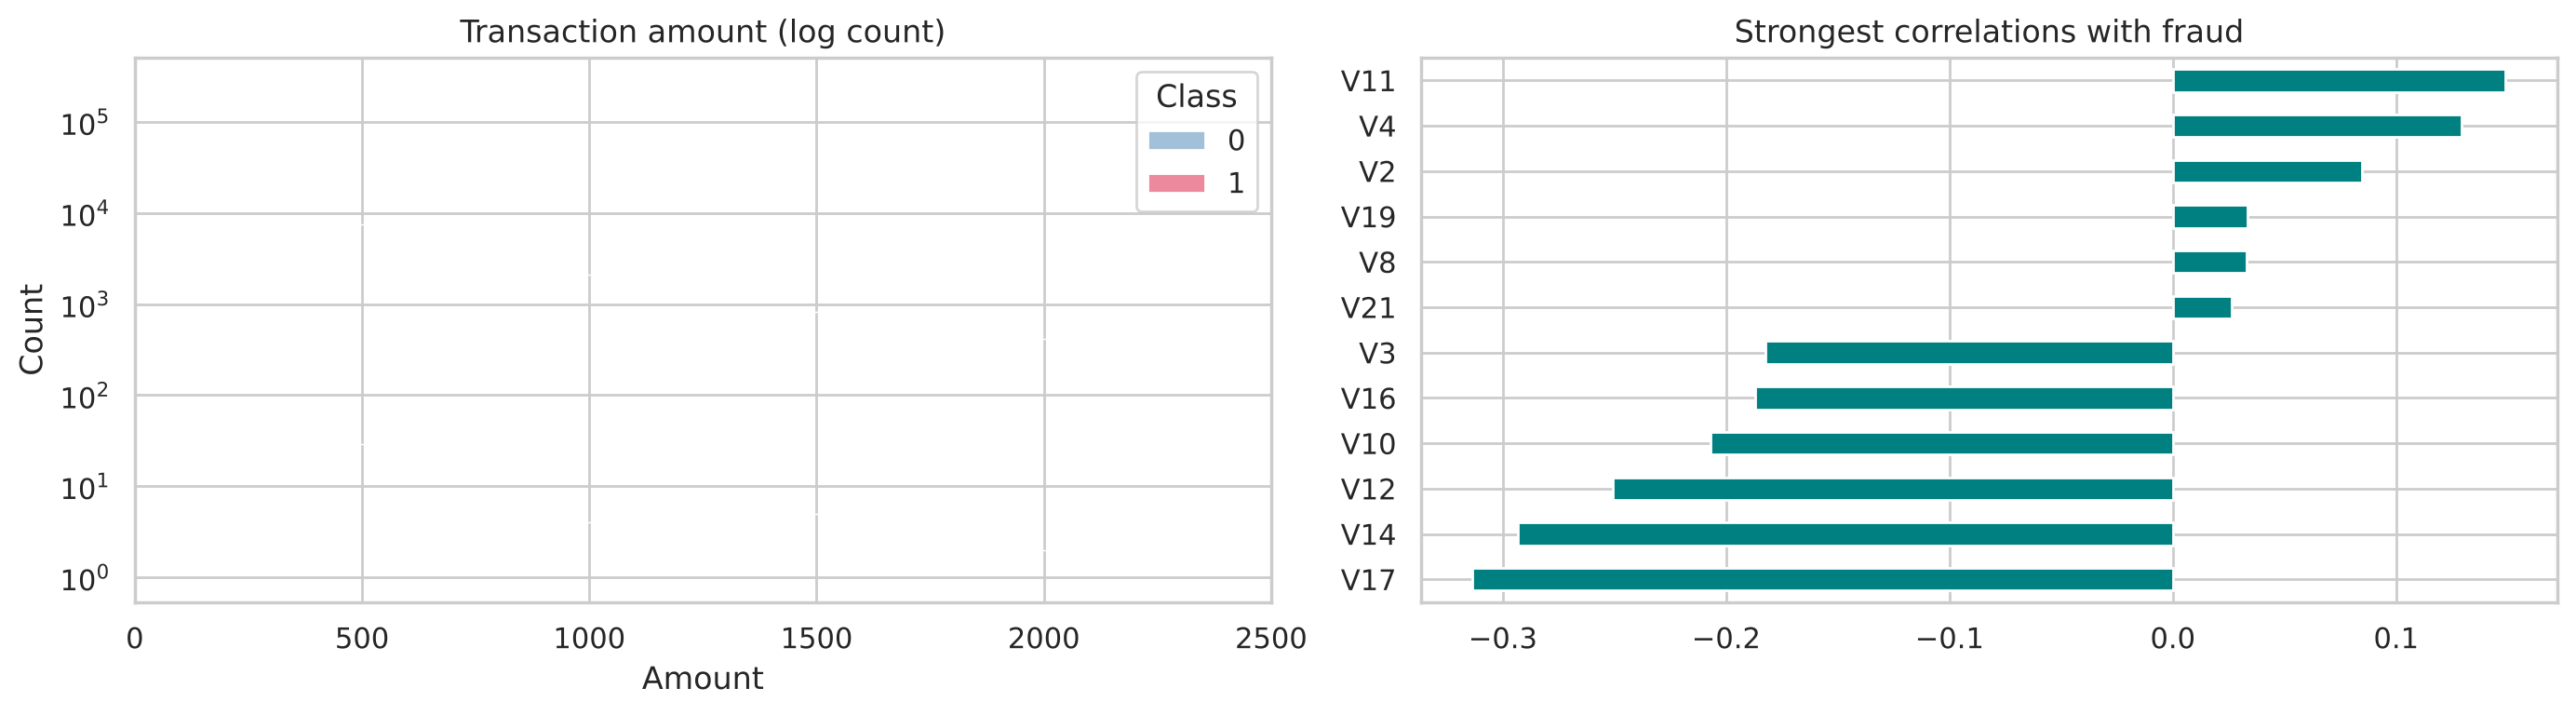

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=df, x="Amount", hue="Class", bins=60, log_scale=(False, True), ax=axes[0], palette=["steelblue", "crimson"])
axes[0].set_xlim(0, 2500); axes[0].set_title("Transaction amount (log count)")
corr = df.corr()["Class"].drop("Class").sort_values()
pd.concat([corr.head(6), corr.tail(6)]).plot(kind="barh", ax=axes[1], color="teal"); axes[1].set_title("Strongest correlations with fraud")
plt.tight_layout(); plt.savefig("images/eda.png", dpi=120, bbox_inches="tight"); plt.show()

* Fraud amounts are mostly small — fraudsters often test a card with low amounts.
* A few PCA components (`V14`, `V17`, `V12`, `V10` negative; `V11`, `V4` positive) separate fraud best.
* **Accuracy is meaningless here:** a model that says "never fraud" is 99.8% accurate. We judge models on **precision, recall and PR-AUC** for the fraud class.

## 3. Train / test split (stratified)

In [4]:
X = df.drop(columns="Class"); y = df["Class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
print("Fraud cases in test set:", y_test.sum())

Fraud cases in test set: 95


## 4. Approach 1 — Isolation Forest (unsupervised)
Trains **without labels**: it isolates points that are easy to separate from the rest. `contamination` is set to the observed fraud rate.

In [5]:
iso = IsolationForest(n_estimators=200, contamination=y_train.mean(), random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_s)
iso_pred = (iso.predict(X_test_s) == -1).astype(int)
iso_score = -iso.score_samples(X_test_s)
print(classification_report(y_test, iso_pred, target_names=["Normal", "Fraud"], digits=3))
print("PR-AUC:", round(average_precision_score(y_test, iso_score), 3))

              precision    recall  f1-score   support

      Normal      0.999     0.999     0.999     56651
       Fraud      0.202     0.189     0.196        95

    accuracy                          0.997     56746
   macro avg      0.600     0.594     0.597     56746
weighted avg      0.997     0.997     0.997     56746

PR-AUC: 0.104


Isolation Forest catches only a small fraction of fraud (an earlier version of this notebook reached ~34% recall; with a stratified split and duplicates removed it is ~19%): many frauds don't *look* unusual overall — they only differ on a few specific components. Labels help a lot here.

## 5. Approach 2 — XGBoost (supervised, class-weighted)
`scale_pos_weight` = (#normal / #fraud) tells the model a missed fraud costs ~580× more than a missed normal transaction.

In [6]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.9, colsample_bytree=0.8,
                    scale_pos_weight=spw, eval_metric="aucpr", n_jobs=-1, random_state=RANDOM_STATE, tree_method="hist")
xgb.fit(X_train_s, y_train)
xgb_proba = xgb.predict_proba(X_test_s)[:, 1]
xgb_pred = (xgb_proba >= 0.5).astype(int)
print(classification_report(y_test, xgb_pred, target_names=["Normal", "Fraud"], digits=3))
print("PR-AUC:", round(average_precision_score(y_test, xgb_proba), 3))

              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000     56651
       Fraud      0.894     0.800     0.844        95

    accuracy                          1.000     56746
   macro avg      0.947     0.900     0.922     56746
weighted avg      0.999     1.000     0.999     56746

PR-AUC: 0.822


### Choosing the decision threshold
The default 0.5 threshold isn't sacred. We pick the threshold that maximises F1 on a **validation split of the training data** (never the test set), then report test results.

In [7]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train_s, y_train, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train)
xgb_val = XGBClassifier(**xgb.get_params()).fit(X_tr, y_tr)
p, r, t = precision_recall_curve(y_val, xgb_val.predict_proba(X_val)[:, 1])
f1s = 2 * p * r / (p + r + 1e-9)
best_t = float(t[np.argmax(f1s[:-1])])
print(f"Best threshold on validation: {best_t:.2f}")
xgb_pred_t = (xgb_proba >= best_t).astype(int)
print(classification_report(y_test, xgb_pred_t, target_names=["Normal", "Fraud"], digits=3))

Best threshold on validation: 0.90
              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000     56651
       Fraud      0.986     0.758     0.857        95

    accuracy                          1.000     56746
   macro avg      0.993     0.879     0.928     56746
weighted avg      1.000     1.000     1.000     56746



## 6. Comparison

In [8]:
rows = []
for name, pred, score in [("Isolation Forest (unsupervised)", iso_pred, iso_score),
                          ("XGBoost (threshold 0.5)", xgb_pred, xgb_proba),
                          (f"XGBoost (tuned threshold {best_t:.2f})", xgb_pred_t, xgb_proba)]:
    rows.append({"model": name, "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred), "PR-AUC": average_precision_score(y_test, score),
                 "frauds caught": f"{int(((pred == 1) & (y_test == 1)).sum())}/{int(y_test.sum())}",
                 "false alarms": int(((pred == 1) & (y_test == 0)).sum())})
comparison = pd.DataFrame(rows).round(3); comparison

,model,precision,recall,F1,PR-AUC,frauds caught,false alarms
0,Isolation Forest (unsupervised),0.202,0.189,0.196,0.104,18/95,71
1,XGBoost (threshold 0.5),0.894,0.800,0.844,0.822,76/95,9
2,XGBoost (tuned threshold 0.90),0.986,0.758,0.857,0.822,72/95,1


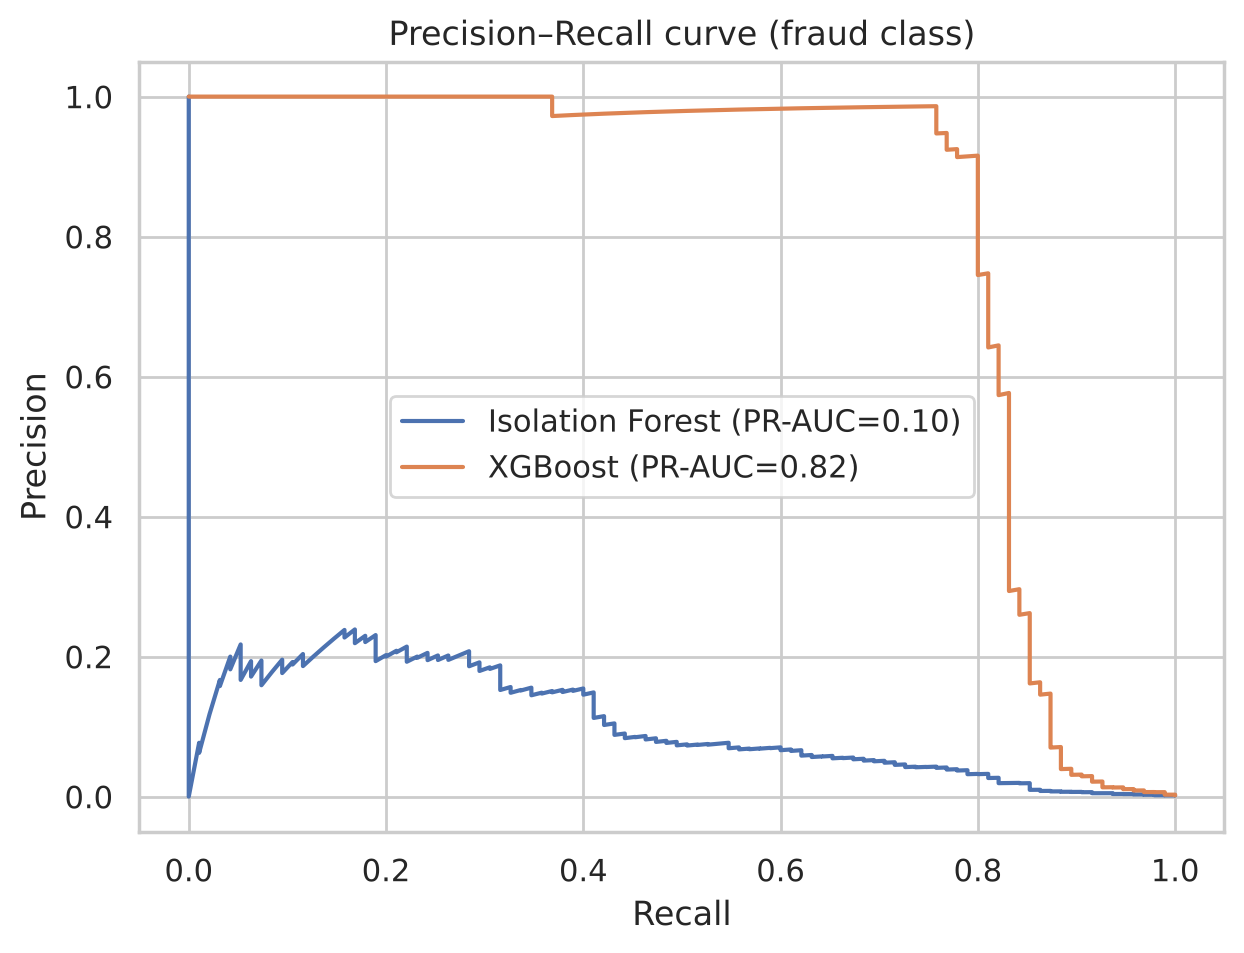

In [9]:
plt.figure(figsize=(7, 5))
for name, score in [("Isolation Forest", iso_score), ("XGBoost", xgb_proba)]:
    p_, r_, _ = precision_recall_curve(y_test, score)
    plt.plot(r_, p_, label=f"{name} (PR-AUC={average_precision_score(y_test, score):.2f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision–Recall curve (fraud class)"); plt.legend()
plt.savefig("images/pr_curve.png", dpi=120, bbox_inches="tight"); plt.show()

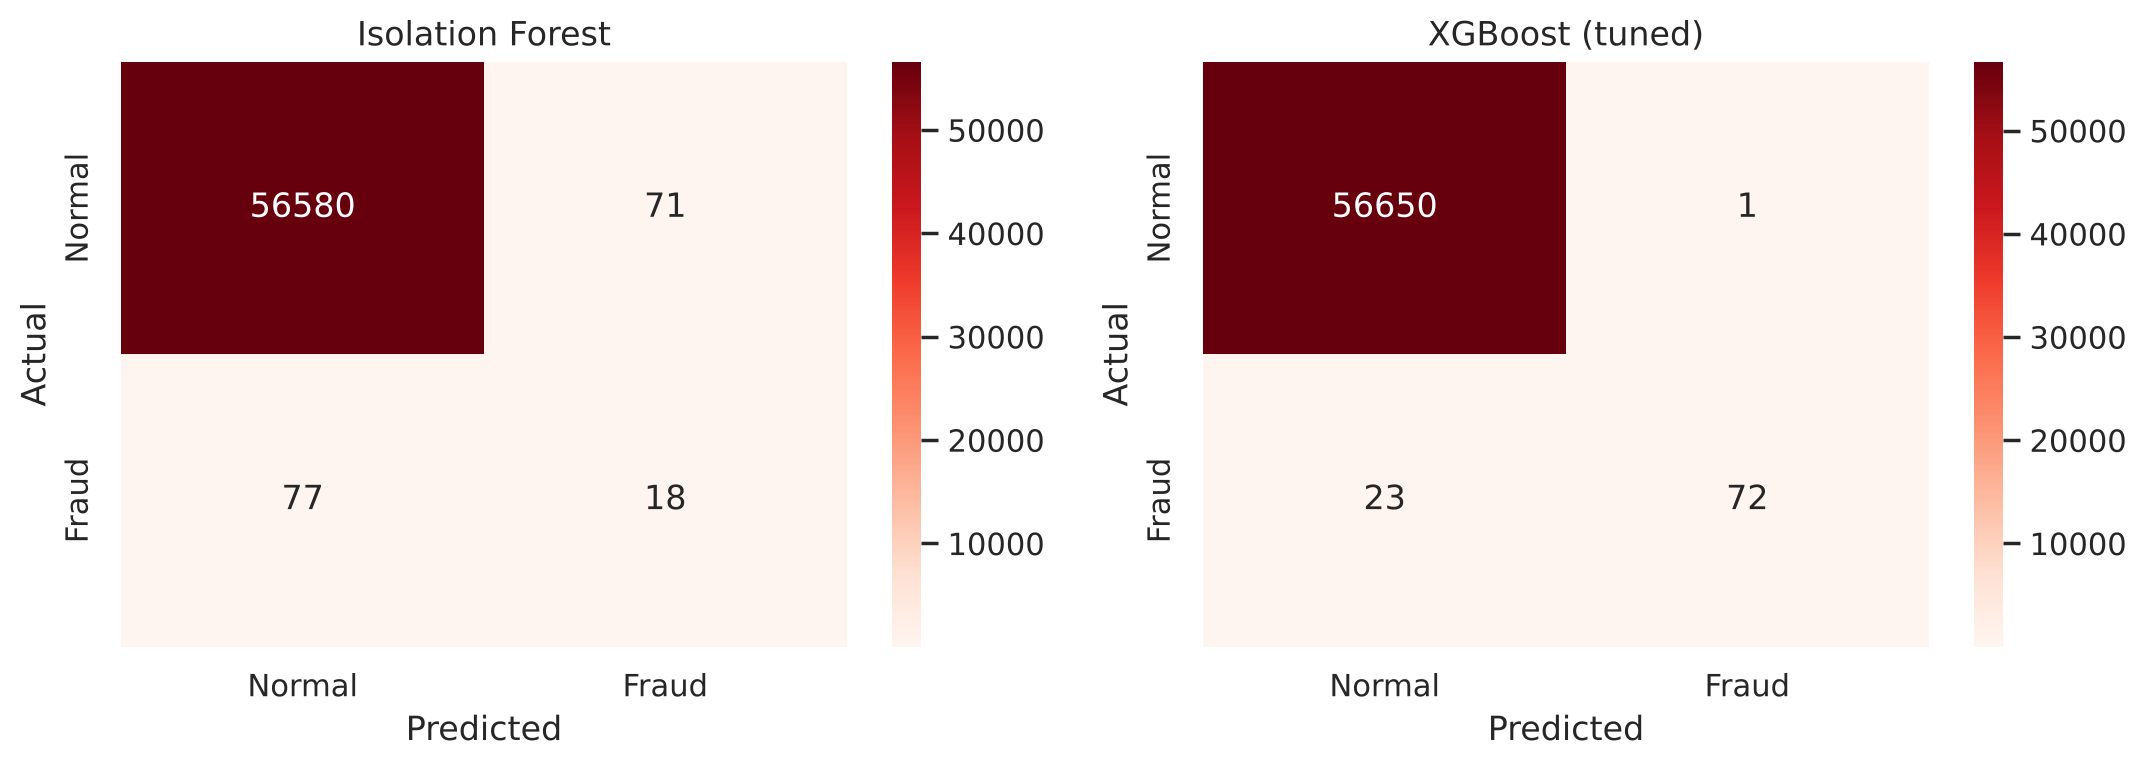

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, pred) in zip(axes, [("Isolation Forest", iso_pred), ("XGBoost (tuned)", xgb_pred_t)]):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Reds", ax=ax, xticklabels=["Normal", "Fraud"], yticklabels=["Normal", "Fraud"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.savefig("images/confusion_matrices.png", dpi=120, bbox_inches="tight"); plt.show()

## 7. Conclusion

* **Isolation Forest** is useful when no labels exist (e.g. a brand-new fraud pattern), but it caught only **18 of 95** frauds with 71 false alarms.
* **XGBoost with class weighting** catches **76 of 95** frauds with only 9 false alarms (PR-AUC **0.82 vs 0.10**). With the tuned threshold it reaches **98.6% precision** — just 1 false alarm in 56,651 normal transactions — while still catching 72 frauds.
* In production the two complement each other: the supervised model for known fraud patterns, the anomaly detector as a safety net for new ones.
* The threshold is a **business decision**: lower it to catch more fraud at the cost of more customers getting a verification SMS.